# Ödev 1 — Veri Temizleme: Çalışanlar (`Calisanlar.xlsx`)

In [106]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Klasör yolları (notebook, notebooks/ klasöründen çalıştırılır)
RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
FIGURES = Path("../figures")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [107]:
# Dosyada birden fazla sayfa (sheet) var; hangisinin kullanılacağına karar vermeden önce hepsini incele
sheets = pd.read_excel(RAW / "Calisanlar.xlsx", sheet_name=None)
for name, sheet in sheets.items():
    print(f"{name!r}: {sheet.shape}")

'data_cleaning_practice_data (2)': (500, 7)
'data_cleaning_practice_dataset': (500, 1)


## 1. Veriyi Keşfetme ve İlk Analiz

In [108]:
# Ham veri: bu bölümde hiç değiştirilmez, tüm tespitler bunun üzerinde yapılır
ham = sheets["data_cleaning_practice_data (2)"]
ham.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Name        500 non-null    str    
 1   Gender      500 non-null    str    
 2   Age         252 non-null    float64
 3   City        500 non-null    str    
 4   Department  500 non-null    str    
 5   Salary      248 non-null    float64
 6   Email       500 non-null    str    
dtypes: float64(2), str(5)
memory usage: 27.5 KB


In [109]:
# Tespit fonksiyonları: veriyi sadece okur, hiçbir şeyi değiştirmez
metin_sutunlari = ham.select_dtypes(include=["object", "string"]).columns


def bosluk_raporu(veri):
    """Her metin sütununda başında / sonunda boşluk olan hücre sayısı."""
    satirlar = []
    for sutun in metin_sutunlari:
        degerler = veri[sutun].dropna().astype(str)
        satirlar.append({
            "Sütun": sutun,
            "Baştaki boşluk": (degerler != degerler.str.lstrip()).sum(),
            "Sondaki boşluk": (degerler != degerler.str.rstrip()).sum(),
        })
    return pd.DataFrame(satirlar)


def harf_raporu(veri):
    """Yalnızca büyük / küçük harf farkı yüzünden ayrı görünen değerler."""
    satirlar = []
    for sutun in metin_sutunlari:
        degerler = veri[sutun].dropna().astype(str)
        for anahtar, grup in degerler.groupby(degerler.str.lower()):
            yazimlar = grup.value_counts()
            if len(yazimlar) > 1:
                satirlar.append({
                    "Sütun": sutun,
                    "Değer": anahtar,
                    "Yazım biçimleri": ", ".join(f"{y!r} ({n})" for y, n in yazimlar.items()),
                    "Kayıt sayısı": len(grup),
                })
    return pd.DataFrame(satirlar, columns=["Sütun", "Değer", "Yazım biçimleri", "Kayıt sayısı"])


# Eksik anlamına gelen yazılar (harften bağımsız karşılaştırılır)
EKSIK_IFADELER = {"na", "n/a", "#n/a", "nan", "null", "none", "nil", "unknown",
                  "missing", "undefined", "bilinmiyor", "yok"}
# Sayısal sütunlarda sık kullanılan yer tutucu sayılar
YER_TUTUCU_SAYILAR = {99, 999, 9999, 99999, 999999}


def metin_eksik_kurallari(degerler):
    """Metin değerleri için gizli eksik kuralları: {neden: hangi değerlerin uyduğu}."""
    normal = degerler.str.strip().str.lower()
    return {
        "eksik ifadesi": normal.isin(EKSIK_IFADELER),
        "harf / rakam yok": ~normal.str.contains(r"[^\W_]"),  # "", "?", "-" gibi
    }


def sayisal_eksik_kurallari(degerler):
    """Sayısal değerler için şüpheli değer kuralları: {neden: hangi değerlerin uyduğu}."""
    return {
        "sıfır veya negatif": degerler <= 0,
        "yer tutucu sayı": degerler.isin(YER_TUTUCU_SAYILAR),
    }


def gizli_eksik_raporu(veri):
    """Null görünmeyen ama eksik anlamına gelebilecek değerler ve kaç kez geçtikleri."""
    kontroller = [(sutun, metin_eksik_kurallari, veri[sutun].dropna().astype(str))
                  for sutun in metin_sutunlari]
    kontroller += [(sutun, sayisal_eksik_kurallari, veri[sutun].dropna())
                   for sutun in veri.select_dtypes(include="number").columns]
    satirlar = []
    for sutun, kurallar, degerler in kontroller:
        for neden, maske in kurallar(degerler).items():
            for deger, sayi in degerler[maske].value_counts().items():
                satirlar.append({"Sütun": sutun, "Değer": repr(deger), "Neden": neden, "Kayıt sayısı": sayi})
    return pd.DataFrame(satirlar, columns=["Sütun", "Değer", "Neden", "Kayıt sayısı"])


def yas_raporu(veri):
    """Age sütununun aralığı ve 10'un katı olan değerlerin oranı (10 ile çarpılmış kayıt belirtisi)."""
    yas = veri["Age"].dropna()
    return pd.DataFrame({
        "Dolu değer": [len(yas)],
        "Farklı değer": [yas.nunique()],
        "En küçük": [yas.min()],
        "En büyük": [yas.max()],
        "10'un katı olan (%)": [100 * (yas % 10 == 0).mean()],
    })

In [110]:
# Temizlik fonksiyonları: aldıkları tabloyu değiştirmez, temizlenmiş yeni bir tablo döndürür
def bosluklari_temizle(veri):
    """Metin sütunlarındaki baştaki ve sondaki boşlukları atar."""
    veri = veri.copy()
    for sutun in metin_sutunlari:
        veri[sutun] = veri[sutun].str.strip()
    return veri


def gizli_eksikleri_bosalt(veri):
    """Metin sütunlarında eksik anlamına gelen değerleri NaN'a çevirir.
    Sayısal şüpheli değerlere dokunmaz: onların eksik mi aykırı mı olduğu ayrıca karar gerektirir."""
    veri = veri.copy()
    for sutun in metin_sutunlari:
        degerler = veri[sutun].dropna().astype(str)
        eksik = pd.DataFrame(metin_eksik_kurallari(degerler)).any(axis=1)  # herhangi bir kurala uyan
        veri[sutun] = veri[sutun].mask(eksik.reindex(veri.index, fill_value=False))
    return veri


def harfleri_duzelt(veri):
    """Küçük harfli hali aynı olan değerleri, o gruptaki en sık geçen yazıma çevirir."""
    veri = veri.copy()
    for sutun in metin_sutunlari:
        anahtar = veri[sutun].str.lower()
        en_sik_yazim = veri[sutun].groupby(anahtar).agg(lambda g: g.mode().iloc[0])
        veri[sutun] = anahtar.map(en_sik_yazim)
    return veri


def yasi_ondan_bol(veri):
    """Age değerleri 10 ile çarpılmış kaydedilmiş (200-600); gerçek yaşa (20-60) çevirmek için 10'a böler."""
    veri = veri.copy()
    veri["Age"] = veri["Age"] / 10
    return veri


def yasi_tamsayi_yap(veri):
    """Age sütununu boş değer tutabilen tam sayı tipine (Int64) çevirir.
    Kesirli yaşlar aşağı yuvarlanır (25.5 -> 25); boş değerler boş kalır."""
    veri = veri.copy()
    veri["Age"] = np.floor(veri["Age"]).astype("Int64")
    return veri

### 1.1 Tespit (ham veri)

In [111]:
bosluk_raporu(ham)

,Sütun,Baştaki boşluk,Sondaki boşluk
0,Name,0,0
1,Gender,0,0
2,City,0,0
3,Department,59,59
4,Email,0,0


In [112]:
# Boşluklar yalnızca karşılaştırma için geçici olarak atılıyor; ham değişmiyor
harf_raporu(bosluklari_temizle(ham))

,Sütun,Değer,Yazım biçimleri,Kayıt sayısı
0,City,islamabad,"'Islamabad' (97), 'islamabad' (9)",106
1,City,karachi,"'Karachi' (87), 'karachi' (10)",97
2,City,lahore,"'Lahore' (81), 'lahore' (10)",91
3,City,peshawar,"'Peshawar' (92), 'peshawar' (12)",104
4,City,quetta,"'Quetta' (93), 'quetta' (9)",102


> **Not:** Gizli eksik değerler puanlamada 2. kriterin (Eksik Verilerin Tespiti) konusu, aynı kontrol 2. bölümde de var. Tekrar eden e-postalı kayıtların karşılaştırması (1.4) bu değerlerin bilinmesine bağlı olduğu için şimdilik burada da çalıştırılıyor.

In [113]:
gizli_eksik_raporu(ham)

,Sütun,Değer,Neden,Kayıt sayısı


> **Yanlış veri tipi — `Age`:** Yaş tam sayı olmalı, ancak sütun `float64` olarak okunuyor. Pandas'ın klasik `int64` tipi boş değer (NaN) tutamadığı için, boş hücre içeren tam sayı sütunları ondalıklı tipe çevrilir. Düzeltme için `yasi_tamsayi_yap` fonksiyonu tanımlandı (boş değer tutabilen `Int64` tipine çevirir); şimdilik uygulanmıyor, ileride gerekirse kullanılacak.

In [114]:
# Yaşların hepsi 10'un katıysa ve 200-600 aralığındaysa değerler 10 ile çarpılmış kaydedilmiştir
yas_raporu(ham)

,Dolu değer,Farklı değer,En küçük,En büyük,10'un katı olan (%)
0,252,41,200.0,600.0,100.0


### 1.2 Temizlik

In [115]:
# ham'dan yeni bir tablo üret: boşlukları temizle, gizli eksikleri NaN yap, harfleri düzelt, yaşı 10'a böl
df = (
    ham
    .pipe(bosluklari_temizle)
    .pipe(gizli_eksikleri_bosalt)
    .pipe(harfleri_duzelt)
    .pipe(yasi_ondan_bol)
)

### 1.3 Doğrulama (temizlenmiş veri)

In [116]:
# Bütün sayılar 0 olmalı
bosluk_raporu(df)

,Sütun,Baştaki boşluk,Sondaki boşluk
0,Name,0,0
1,Gender,0,0
2,City,0,0
3,Department,0,0
4,Email,0,0


In [117]:
# Tablo boş olmalı
harf_raporu(df)

,Sütun,Değer,Yazım biçimleri,Kayıt sayısı


In [118]:
# Metin kurallarına uyan satır kalmamalı (sayısal şüpheliler bilerek çevrilmiyor, varsa burada görünür)
gizli_eksik_raporu(df)

,Sütun,Değer,Neden,Kayıt sayısı


In [119]:
# Yaşlar 20-60 aralığında olmalı; dolu değer sayısı değişmemeli
yas_raporu(df)

,Dolu değer,Farklı değer,En küçük,En büyük,10'un katı olan (%)
0,252,41,20.0,60.0,9.52381


### 1.4 Tekrar eden e-postalar

In [120]:
# Temizlenmiş veri üzerinde: harf ve boşluk farkları zaten giderildiği için ek normalleştirme gerekmiyor
eposta = df["Email"].dropna()
tekrar_sayilari = eposta.value_counts()
tekrar_eden_epostalar = tekrar_sayilari[tekrar_sayilari > 1]

print(f"Boş olmayan e-posta: {len(eposta)}")
print(f"Farklı e-posta: {eposta.nunique()}")
print(f"Birden fazla kayıtta geçen e-posta: {len(tekrar_eden_epostalar)} "
      f"(toplam {tekrar_eden_epostalar.sum()} kayıt)")

tekrar_eden_epostalar.rename_axis("Email").reset_index(name="Kayıt sayısı")

Boş olmayan e-posta: 500
Farklı e-posta: 408
Birden fazla kayıtta geçen e-posta: 75 (toplam 167 kayıt)


,Email,Kayıt sayısı
0,ayesha95@gmail.com,5
1,tariq82@gmail.com,5
2,hina58@gmail.com,4
3,ahmed44@gmail.com,3
4,tariq17@gmail.com,3
...,...,...
70,sara54@gmail.com,2
71,ali98@gmail.com,2
72,sara44@gmail.com,2
73,sana53@gmail.com,2


In [121]:
# Aynı e-postaya sahip kayıtları karşılaştır. Null "bilinmiyor" sayılır, hiçbir değerle çelişmez:
# bir grupta her sütunda en fazla bir farklı dolu değer varsa o sütun tutarlıdır (nunique null'ları saymaz).
diger_sutunlar = df.columns.drop("Email")
tekrarlar = df[df["Email"].notna() & df["Email"].duplicated(keep=False)]
gruplar = tekrarlar.groupby("Email")

celisen = gruplar[diger_sutunlar].nunique().gt(1)  # iki veya daha fazla farklı dolu değer
bos_var = tekrarlar[diger_sutunlar].isna().groupby(tekrarlar["Email"]).any()

eposta_raporu = pd.DataFrame({
    "Kayıt sayısı": gruplar.size(),
    "Kategori": pd.Series(
        np.select([celisen.any(axis=1), bos_var.any(axis=1)], ["çelişkili", "null dışında aynı"], default="tamamen aynı"),
        index=celisen.index,
    ),
    "Çelişen sütunlar": celisen.apply(lambda satir: ", ".join(satir.index[satir]), axis=1),
    "Boş içeren sütunlar": bos_var.apply(lambda satir: ", ".join(satir.index[satir]), axis=1),
})

print(eposta_raporu["Kategori"].value_counts().to_string(), end="\n\n")
eposta_raporu.sort_values(["Kategori", "Email"])

Kategori
çelişkili            73
null dışında aynı     2



,Kayıt sayısı,Kategori,Çelişen sütunlar,Boş içeren sütunlar
Email,,,,
ahmed80@gmail.com,2,null dışında aynı,,"Age, Salary"
sara60@gmail.com,2,null dışında aynı,,"Age, Salary"
ahmed13@gmail.com,3,çelişkili,"Gender, Age, City, Department",Salary
ahmed2@gmail.com,2,çelişkili,"City, Department","Age, Salary"
ahmed35@gmail.com,2,çelişkili,"Gender, Age, Department, Salary",
...,...,...,...,...
zara3@gmail.com,2,çelişkili,"Gender, Age, City, Department",Salary
zara63@gmail.com,2,çelişkili,"Age, City, Department, Salary",
zara69@gmail.com,2,çelişkili,"City, Department","Age, Salary"


In [122]:
# Boş değer içeren gruplardaki kayıtların tamamı: boşlukların gruptaki hangi değerlerle "eşleştiğini" görmek için
bos_iceren_epostalar = eposta_raporu.index[eposta_raporu["Boş içeren sütunlar"] != ""]
(
    tekrarlar[tekrarlar["Email"].isin(bos_iceren_epostalar)]
    .join(eposta_raporu["Kategori"], on="Email")
    .sort_values(["Kategori", "Email"])
)

,Name,Gender,Age,City,Department,Salary,Email,Kategori
53,Ahmed,Female,57.0,Lahore,IT,NaN,ahmed80@gmail.com,null dışında aynı
498,Ahmed,Female,NaN,Lahore,IT,8291536.0,ahmed80@gmail.com,null dışında aynı
148,Sara,Male,NaN,Quetta,Finance,381127.0,sara60@gmail.com,null dışında aynı
370,Sara,Male,25.0,Quetta,Finance,NaN,sara60@gmail.com,null dışında aynı
270,Ahmed,Male,39.0,Quetta,HR,10473277.0,ahmed13@gmail.com,çelişkili
...,...,...,...,...,...,...,...,...
423,Zara,Female,52.0,Karachi,Finance,NaN,zara97@gmail.com,çelişkili
427,Zara,Female,NaN,Quetta,Marketing,10916425.0,zara97@gmail.com,çelişkili
73,Zara,Female,NaN,Karachi,HR,NaN,zara99@gmail.com,çelişkili
124,Zara,Female,45.0,Quetta,Sales,5021298.0,zara99@gmail.com,çelişkili


> **Karar — tekrar eden e-postalar:** Aynı e-postaya sahip 75 grubun 73'ü en az bir sütunda çelişiyor, yani bunlar aynı kişinin tekrar eden kayıtları değil, aynı e-posta adresini paylaşan farklı kişiler. Yalnızca 2 grup boş değerler dışında tutarlı. Tekrar eden e-postaların veriye bir katkısı olmadığı değerlendirildiği için bu kayıtlara dokunulmadı, hiçbir satır silinmedi veya birleştirilmedi.

## 2. Eksik Verilerin Tespiti ve Görselleştirilmesi

In [123]:
gizli_eksik_raporu(ham)

,Sütun,Değer,Neden,Kayıt sayısı


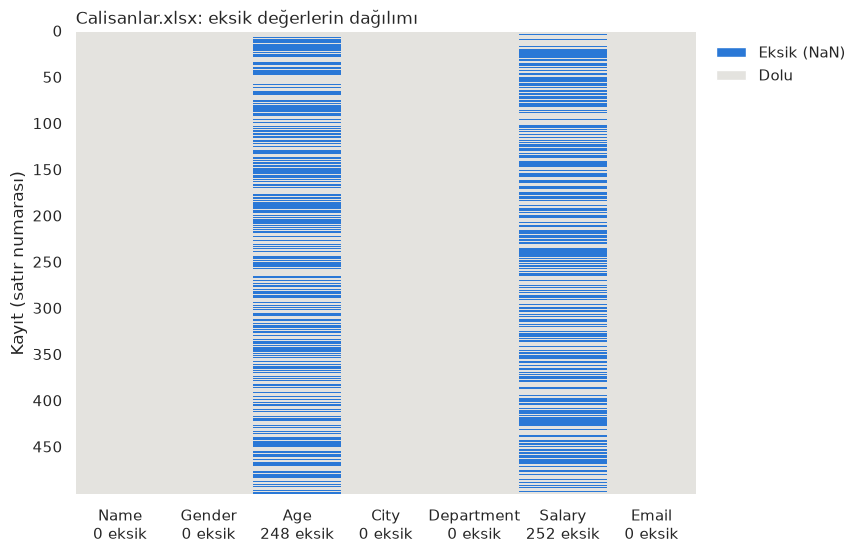

In [124]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Görünür eksik değerler (NaN): her satır bir kayıt, her sütun bir değişken
DOLU_RENK, EKSIK_RENK = "#e4e3df", "#2a78d6"
eksik = ham.isna()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(eksik.astype(int), cmap=ListedColormap([DOLU_RENK, EKSIK_RENK]), vmin=0, vmax=1,
            cbar=False, yticklabels=50, ax=ax)
ax.set_xticklabels([f"{sutun}\n{sayi} eksik" for sutun, sayi in eksik.sum().items()], rotation=0)
ax.set_xlabel("")
ax.set_ylabel("Kayıt (satır numarası)")
ax.tick_params(axis="y", rotation=0)
ax.set_title("Calisanlar.xlsx: eksik değerlerin dağılımı", loc="left")
ax.legend(handles=[Patch(facecolor=EKSIK_RENK, label="Eksik (NaN)"),
                   Patch(facecolor=DOLU_RENK, label="Dolu")],
          loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)

fig.savefig(FIGURES / "calisanlar_eksik_isi_haritasi.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Eksik Veri Stratejisi ve Uygulama

### 3.1 Ön kontrol: diğer sütunlar `Age` ve `Salary`'yi açıklıyor mu?

In [125]:
import statsmodels.formula.api as smf

# Diğer sütunlar Age ve Salary'yi açıklıyor mu? (KNN ve regresyonla doldurmanın ön koşulu)
# Her model yalnızca kullandığı sütunların hepsi dolu olan satırlarla kurulur.
eksik_sutunlar = ["Age", "Salary"]
kategorikler = "C(Gender) + C(City) + C(Department)"
modeller = {
    "Age ~ kategorikler": f"Age ~ {kategorikler}",
    "Age ~ kategorikler + Salary": f"Age ~ {kategorikler} + Salary",
    "Salary ~ kategorikler": f"Salary ~ {kategorikler}",
    "Salary ~ kategorikler + Age": f"Salary ~ {kategorikler} + Age",
}
r2_tablosu = pd.DataFrame([
    {"Model": ad, "Satır sayısı": int(sonuc.nobs), "R²": sonuc.rsquared, "Düzeltilmiş R²": sonuc.rsquared_adj}
    for ad, sonuc in ((ad, smf.ols(formul, data=df).fit()) for ad, formul in modeller.items())
]).set_index("Model")
r2_tablosu.round(3)

,Satır sayısı,R²,Düzeltilmiş R²
Model,,,
Age ~ kategorikler,252,0.038,0.002
Age ~ kategorikler + Salary,124,0.093,0.013
Salary ~ kategorikler,248,0.007,-0.030
Salary ~ kategorikler + Age,124,0.032,-0.054


> **KNN ve regresyonla doldurma neden kullanılmadı:** KNN, eksik bir değeri diğer sütunlarda o kayda en çok benzeyen *k* kaydın ortalamasıyla doldurur. Bu yaklaşım ancak benzerliğin ölçüldüğü sütunlar hedef sütunla ilişkiliyse anlamlıdır. Yukarıdaki doğrusal modeller, `Gender`, `City` ve `Department` (ve diğer sayısal sütun) birlikte kullanıldığında bile `Age` ve `Salary`'deki değişimin neredeyse hiçbirini açıklamadığını gösteriyor: düzeltilmiş R² değerleri 0'a çok yakın (en yüksek ≈ 0,01), bazıları negatif. Bu durumda KNN'in bulacağı "en yakın komşular" rastgele seçilmiş kayıtlardan farksız olur; doldurulan değerler rastgele *k* değerin ortalamasına, dolayısıyla genel ortalamaya yakınsar ve dağılımı daraltır. Aynı gerekçe regresyonla doldurma için de geçerlidir: R² ≈ 0 olan bir modelin tahminleri pratikte genel ortalamadır. Bu nedenle iki yöntem de karşılaştırmaya alınmadı.

### 3.2 Yöntem karşılaştırması: ortalama, medyan, rastgele örnekleme

In [126]:
# Doldurma fonksiyonları: aldıkları tabloyu değiştirmez, doldurulmuş yeni bir tablo döndürür
def ortalama_ile_doldur(veri):
    """Eksik hücreleri sütunun ortalamasıyla doldurur."""
    veri = veri.copy()
    for sutun in eksik_sutunlar:
        veri[sutun] = veri[sutun].fillna(veri[sutun].mean())
    return veri


def medyan_ile_doldur(veri):
    """Eksik hücreleri sütunun medyanıyla doldurur."""
    veri = veri.copy()
    for sutun in eksik_sutunlar:
        veri[sutun] = veri[sutun].fillna(veri[sutun].median())
    return veri


def rastgele_ornekle_doldur(veri, seed=42):
    """Eksik hücreleri, aynı sütunun dolu değerlerinden rastgele (yerine koyarak) seçilen değerlerle doldurur.
    Sabit seed: her çalıştırmada aynı sonuç."""
    veri = veri.copy()
    rng = np.random.default_rng(seed)
    for sutun in eksik_sutunlar:
        eksik = veri[sutun].isna()
        veri.loc[eksik, sutun] = rng.choice(veri[sutun].dropna().to_numpy(), size=eksik.sum())
    return veri


yontemler = {
    "Ortalama": ortalama_ile_doldur,
    "Medyan": medyan_ile_doldur,
    "Rastgele örnekleme": rastgele_ornekle_doldur,
}
doldurulmus = {ad: yontem(df) for ad, yontem in yontemler.items()}

In [127]:
# Her yöntemden sonra ortalama ve standart sapma; orijinal = yalnızca dolu (gözlenen) değerler
ozet = {"Orijinal (dolu değerler)": df[eksik_sutunlar]} | {ad: v[eksik_sutunlar] for ad, v in doldurulmus.items()}
karsilastirma = pd.concat({ad: v.agg(["mean", "std"]).T.stack() for ad, v in ozet.items()}, axis=1).T
karsilastirma.columns = [f"{sutun} {'ortalama' if olcu == 'mean' else 'std'}" for sutun, olcu in karsilastirma.columns]
for sutun in eksik_sutunlar:
    orijinal_std = df[sutun].std()
    karsilastirma[f"{sutun} std değişimi (%)"] = 100 * (karsilastirma[f"{sutun} std"] / orijinal_std - 1)
karsilastirma.round(1)

,Age ortalama,Age std,Salary ortalama,Salary std,Age std değişimi (%),Salary std değişimi (%)
Orijinal (dolu değerler),40.4,11.4,8306032.9,4370873.4,0.0,0.0
Ortalama,40.4,8.1,8306032.9,3075150.9,-29.1,-29.6
Medyan,40.7,8.1,8568040.9,3086137.9,-29.0,-29.4
Rastgele örnekleme,40.3,11.6,8056614.4,4432337.1,2.4,1.4


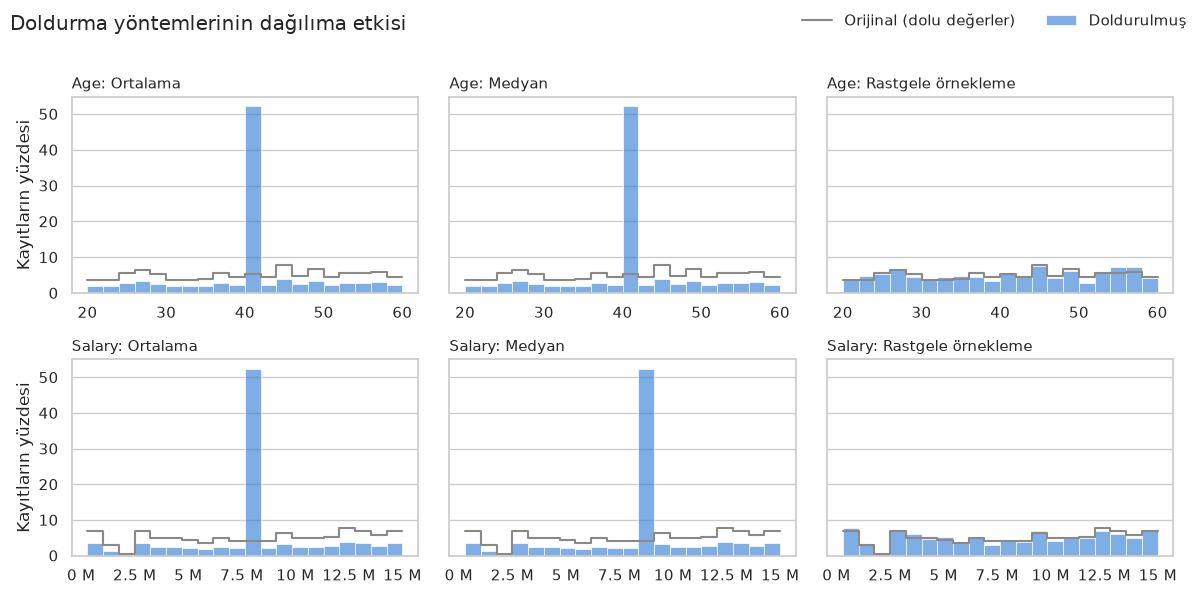

In [128]:
from matplotlib.ticker import FuncFormatter

# Her panel: orijinal dolu değerlerin dağılımı (gri çizgi) ve yöntem uygulandıktan sonraki dağılım (mavi)
ORIJINAL_RENK, DOLDURULMUS_RENK = "#8a8985", "#2a78d6"
fig, axes = plt.subplots(len(eksik_sutunlar), len(yontemler), figsize=(12, 6), sharey="row")
for satir, sutun in enumerate(eksik_sutunlar):
    kutular = np.histogram_bin_edges(df[sutun].dropna(), bins=20)  # aynı satırdaki paneller aynı kutuları kullanır
    for kolon, (ad, veri) in enumerate(doldurulmus.items()):
        ax = axes[satir, kolon]
        sns.histplot(veri[sutun], bins=kutular, stat="percent", color=DOLDURULMUS_RENK, alpha=0.6,
                     edgecolor="white", linewidth=0.5, ax=ax, label="Doldurulmuş")
        sns.histplot(df[sutun].dropna(), bins=kutular, stat="percent", element="step", fill=False,
                     color=ORIJINAL_RENK, linewidth=1.5, ax=ax, label="Orijinal (dolu değerler)")
        ax.set_title(f"{sutun}: {ad}", loc="left", fontsize=11)
        ax.set_xlabel("")
        ax.set_ylabel("Kayıtların yüzdesi" if kolon == 0 else "")
        ax.grid(axis="x", visible=False)
        if sutun == "Salary":
            ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1e6:g} M"))
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper right", ncol=2, frameon=False)
fig.suptitle("Doldurma yöntemlerinin dağılıma etkisi", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.97))

fig.savefig(FIGURES / "calisanlar_doldurma_karsilastirmasi.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.3 Seçim ve uygulama

> **Seçilen yöntem: rastgele örnekleme.** Ortalama ve medyanla doldurma, her iki sütunda da kayıtların yaklaşık yarısını tek bir değere eşitliyor: histogramda yapay bir tepe oluşuyor ve standart sapma yaklaşık %29 düşüyor (tablo ve grafik). Dağılımlar simetrik olduğu için ortalama ile medyan arasında pratik bir fark yok; ikisi de dağılımı aynı ölçüde bozuyor. Rastgele örneklemede her eksik hücreye aynı sütunun gözlenen değerlerinden rastgele biri atandığı için dağılımın şekli korunuyor; ortalama ve standart sapmadaki değişim birkaç yüzdeyle sınırlı ve örneklemenin rastgeleliğinden kaynaklanıyor. Yöntemin bilinen sınırlılığı, sütunlar arasındaki ilişkileri hesaba katmamasıdır; bu veride hiçbir sütun yaşı ve maaşı açıklamadığından (3.1) bu sınırlılık sonucu etkilemiyor ve daha karmaşık bir yöntemin yararlanabileceği ek bir bilgi de bulunmuyor. Tekrarlanabilirlik için rastgele sayı üreteci sabit bir başlangıç değeriyle (`seed=42`) çalıştırılıyor.

In [129]:
# Seçilen yöntem uygulanıyor; df değişmiyor, sonuç yeni bir tabloya yazılıyor
df_doldurulmus = rastgele_ornekle_doldur(df)

# Kontrol: eksik hücre kalmamalı
df_doldurulmus[eksik_sutunlar].isna().sum()

Age       0
Salary    0
dtype: int64

## 4. Aykırı Değer (Outlier) Analizi

## 5. Temizlik Sonrası Dağılım Kontrolü

## 6. Temiz Verinin Kaydedilmesi

In [130]:
df.to_excel(PROCESSED / "Calisanlar_temiz.xlsx", index=False)